# Data Science Interview

The interview data is preloaded into a SQLite database at `/home/interview/interview.db`.

Run the cells below to connect and explore the available tables. You can query the data directly with SQL via pandas — no need to load any CSV files.

In [1]:
import sqlite3
import pandas as pd

conn = sqlite3.connect("/home/interview/interview.db")
cursor = conn.cursor()
cursor.execute("SELECT * FROM campaigns")

# 4. Fetch all matching rows
rows = cursor.fetchall()

# 5. Loop through and print the results
for row in rows:
    print(row)

(1000, 'brand_01_outdoor_sp', 'brand_01', 'Outdoor', 0.26, '2024-02-21')
(1001, 'brand_02_kitchen_sp', 'brand_02', 'Kitchen', 0.174, '2024-03-24')
(1002, 'brand_02_beauty_sp', 'brand_02', 'Beauty', 0.34, '2024-04-27')
(1003, 'brand_02_outdoor_sp', 'brand_02', 'Outdoor', 0.182, '2024-04-04')
(1004, 'brand_03_pet_sp', 'brand_03', 'Pet', 0.243, '2024-01-22')
(1005, 'brand_03_office_sp', 'brand_03', 'Office', 0.311, '2024-02-18')
(1006, 'brand_03_outdoor_sp', 'brand_03', 'Outdoor', 0.261, '2024-02-24')
(1007, 'brand_04_kitchen_sp', 'brand_04', 'Kitchen', 0.166, '2024-03-07')
(1008, 'brand_05_outdoor_sp', 'brand_05', 'Outdoor', 0.308, '2024-01-20')
(1009, 'brand_05_outdoor_sp', 'brand_05', 'Outdoor', 0.239, '2024-01-09')
(1010, 'brand_05_office_sp', 'brand_05', 'Office', 0.373, '2024-03-22')
(1011, 'brand_06_outdoor_sp', 'brand_06', 'Outdoor', 0.267, '2024-01-24')
(1012, 'brand_06_pet_sp', 'brand_06', 'Pet', 0.189, '2024-01-06')
(1013, 'brand_06_outdoor_sp', 'brand_06', 'Outdoor', 0.336, '2

## See what tables exist

In [2]:
pd.read_sql("SELECT name FROM sqlite_master WHERE type='table'", conn)

,name
0,campaigns
1,ad_performance


## Query away

In [3]:
df = pd.read_sql("SELECT * FROM campaigns WHERE target_acos > 0.1", conn)
df.head()

,campaign_id,campaign_name,brand_id,product_category,target_acos,launch_date
0,1000,brand_01_outdoor_sp,brand_01,Outdoor,0.260,2024-02-21
1,1001,brand_02_kitchen_sp,brand_02,Kitchen,0.174,2024-03-24
2,1002,brand_02_beauty_sp,brand_02,Beauty,0.340,2024-04-27
3,1003,brand_02_outdoor_sp,brand_02,Outdoor,0.182,2024-04-04
4,1004,brand_03_pet_sp,brand_03,Pet,0.243,2024-01-22


### SQL

2. Overspending keywords. Join to campaigns. For each product_category, list keywords whose lifetime ACoS is worse than (greater than) their campaign's target_acos. Return category, keyword, its ACoS, and the target.

In [16]:
query = """
WITH spend_per_keywords AS (
SELECT
    campaigns.campaign_id,
    product_category,
    keyword_text,
    target_acos,
    SUM(sales) / SUM(spend) AS acos
FROM campaigns
LEFT JOIN ad_performance
ON campaigns.campaign_id = ad_performance.campaign_id
GROUP BY campaigns.campaign_id, product_category, keyword_text, target_acos
)
SELECT
    product_category,
    keyword_text,
    target_acos,
    acos
FROM spend_per_keywords
WHERE acos > target_acos
"""

In [17]:
df = pd.read_sql(query, conn)
df.head()

,product_category,keyword_text,target_acos,acos
0,Outdoor,deluxe outdoor,0.26,1.372333
1,Outdoor,eco outdoor,0.26,1.513037
2,Outdoor,everyday outdoor,0.26,1.306402
3,Outdoor,heavy duty outdoor,0.26,1.337478
4,Outdoor,large outdoor,0.26,6.605042


## A few pandas basics

Once your data is in a DataFrame, here are some common starting points.

In [ ]:
# Shape (rows, columns) and column names
print(df.shape)
print(df.columns.tolist())

In [ ]:
# Summary statistics for numeric columns
df.describe()

In [ ]:
# Column types and non-null counts
df.info()

In [ ]:
# Sort by target_acos, highest first
df.sort_values("target_acos", ascending=False).head()

### Python / Pandas

In [280]:
import matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_curve, average_precision_score, PrecisionRecallDisplay
from xgboost import XGBClassifier
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import recall_score
from sklearn.metrics import precision_score

1. Load & clean. Load both files. Identify data-quality problems and decide how to handle each. Explain your choices — some issues you should fix, some you should investigate, some you might keep.

#### Campaigns

In [116]:
campaigns = pd.read_sql("SELECT * FROM campaigns", conn)
campaigns

,campaign_id,campaign_name,brand_id,product_category,target_acos,launch_date
0,1000,brand_01_outdoor_sp,brand_01,Outdoor,0.260,2024-02-21
1,1001,brand_02_kitchen_sp,brand_02,Kitchen,0.174,2024-03-24
2,1002,brand_02_beauty_sp,brand_02,Beauty,0.340,2024-04-27
3,1003,brand_02_outdoor_sp,brand_02,Outdoor,0.182,2024-04-04
4,1004,brand_03_pet_sp,brand_03,Pet,0.243,2024-01-22
5,1005,brand_03_office_sp,brand_03,Office,0.311,2024-02-18
6,1006,brand_03_outdoor_sp,brand_03,Outdoor,0.261,2024-02-24
7,1007,brand_04_kitchen_sp,brand_04,Kitchen,0.166,2024-03-07
8,1008,brand_05_outdoor_sp,brand_05,Outdoor,0.308,2024-01-20
9,1009,brand_05_outdoor_sp,brand_05,Outdoor,0.239,2024-01-09


In [117]:
campaigns.info()

<class 'pandas.DataFrame'>
RangeIndex: 23 entries, 0 to 22
Data columns (total 6 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   campaign_id       23 non-null     int64  
 1   campaign_name     23 non-null     str    
 2   brand_id          23 non-null     str    
 3   product_category  23 non-null     str    
 4   target_acos       23 non-null     float64
 5   launch_date       23 non-null     str    
dtypes: float64(1), int64(1), str(4)
memory usage: 1.2 KB


In [118]:
# Identify null values
campaigns.isna().sum()

campaign_id         0
campaign_name       0
brand_id            0
product_category    0
target_acos         0
launch_date         0
dtype: int64

In [119]:
# Convert date to datetime
campaigns["launch_date"] = pd.to_datetime(campaigns["launch_date"])

In [ ]:
# Remove whitespace and convert to lower case
campaigns["brand_id"] = campaigns["brand_id"].str.strip().str.lower()
campaigns["product_category"] = campaigns["product_category"].str.strip().str.lower()

In [ ]:
# Convert str to category
cat_cols = ['brand_id', 'product_category']

for c in cat_cols:
    campaigns[c] = campaigns[c].astype("category")

In [ ]:
# Campaign name is brand id + product category, redundant information
campaigns["tmp_col"] = campaigns["brand_id"] + "_" + campaigns["product_category"] + "_sp"
campaigns[campaigns["tmp_col"]!=campaigns["campaign_name"]]

In [ ]:
# Campaign name contains duplicate, it is not unique, only campain_id is
campaigns[campaigns.duplicated("campaign_name", keep=False)]

    campaign_id        campaign_name  brand_id product_category  target_acos  \
8          1008  brand_05_outdoor_sp  brand_05          outdoor        0.308   
9          1009  brand_05_outdoor_sp  brand_05          outdoor        0.239   
11         1011  brand_06_outdoor_sp  brand_06          outdoor        0.267   
13         1013  brand_06_outdoor_sp  brand_06          outdoor        0.336   
18         1018  brand_10_kitchen_sp  brand_10          kitchen        0.325   
19         1019  brand_10_kitchen_sp  brand_10          kitchen        0.358   

   launch_date  
8   2024-01-20  
9   2024-01-09  
11  2024-01-24  
13  2024-03-22  
18  2024-04-09  
19  2024-02-07  


In [23]:
campaigns.describe()

,campaign_id,target_acos,launch_date
count,23.00000,23.000000,23
mean,1011.00000,0.266783,2024-03-02 20:52:10.434782
min,1000.00000,0.152000,2024-01-06 00:00:00
25%,1005.50000,0.235000,2024-01-24 00:00:00
50%,1011.00000,0.267000,2024-03-07 00:00:00
75%,1016.50000,0.319000,2024-04-04 12:00:00
max,1022.00000,0.373000,2024-04-27 00:00:00
std,6.78233,0.064149,NaN


In [28]:
# Number of campaign by product category
campaigns["product_category"].value_counts()

product_category
Outdoor        9
Kitchen        4
Pet            4
Office         3
Supplements    2
Beauty         1
Name: count, dtype: int64

#### Ad performance

In [145]:
ad_performance = pd.read_sql("SELECT * FROM ad_performance", conn)
ad_performance.head()

,date,campaign_id,keyword_id,keyword_text,match_type,impressions,clicks,spend,orders,sales,bid
0,2024-05-19,1005,5060,gift office,broad,95,0,0.00,0,0.00,0.71
1,2024-05-14,1022,5205,eco outdoor,phrase,97,4,3.58,1,17.93,0.89
2,2024-06-25,1000,5008,mini outdoor,exact,87,0,0.00,0,0.00,0.78
3,2024-06-06,1000,5005,deluxe outdoor,phrase,240,0,0.00,0,0.00,1.90
4,2024-06-02,1019,5180,starter kitchen,exact,167,2,2.32,0,0.00,1.16


In [146]:
ad_performance.info()

<class 'pandas.DataFrame'>
RangeIndex: 12651 entries, 0 to 12650
Data columns (total 11 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   date          12651 non-null  str    
 1   campaign_id   12651 non-null  int64  
 2   keyword_id    12651 non-null  int64  
 3   keyword_text  12651 non-null  str    
 4   match_type    12651 non-null  str    
 5   impressions   12651 non-null  int64  
 6   clicks        12651 non-null  int64  
 7   spend         12651 non-null  float64
 8   orders        12651 non-null  int64  
 9   sales         12525 non-null  float64
 10  bid           12588 non-null  float64
dtypes: float64(3), int64(5), str(3)
memory usage: 1.1 MB


In [147]:
ad_performance.isna().sum()

date              0
campaign_id       0
keyword_id        0
keyword_text      0
match_type        0
impressions       0
clicks            0
spend             0
orders            0
sales           126
bid              63
dtype: int64

In [148]:
# Get proportion of empty sales
ad_performance[ad_performance["sales"].isna()].shape[0]/ad_performance.shape[0]*100

0.9959686981266304

In [149]:
# Get proportion of empty bid 
ad_performance[ad_performance["bid"].isna()].shape[0]/ad_performance.shape[0]*100

0.4979843490633152

In [150]:
# Remove NA's from sales and bid column
ad_performance = ad_performance.dropna(subset=["sales","bid"])

In [151]:
# Replace negative spend by median
ad_performance["spend"] = np.where(ad_performance["spend"] < 0, ad_performance["spend"].median(), ad_performance["spend"])

In [152]:
# Convert date to datetime
ad_performance["date"] = pd.to_datetime(ad_performance["date"])

In [153]:
# Drop duplicated rows
ad_performance = ad_performance.drop_duplicates()

In [154]:
ad_performance.describe()

,date,campaign_id,keyword_id,impressions,clicks,spend,orders,sales,bid
count,12400,12400.00000,12400.000000,12400.000000,12400.000000,12400.000000,12400.000000,12400.000000,12400.000000
mean,2024-05-30 11:54:25.548387,1010.37250,5104.392581,104.871210,1.021774,1.068408,0.108629,3.050204,0.874494
min,2024-05-01 00:00:00,1000.00000,5000.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.100000
25%,2024-05-15 18:00:00,1005.00000,5052.000000,68.000000,0.000000,0.000000,0.000000,0.000000,0.590000
50%,2024-05-31 00:00:00,1010.00000,5104.000000,103.000000,1.000000,0.610000,0.000000,0.000000,0.860000
75%,2024-06-14 00:00:00,1016.00000,5157.000000,139.000000,2.000000,1.500000,0.000000,0.000000,1.140000
max,2024-06-29 00:00:00,1022.00000,5209.000000,283.000000,9.000000,15.630000,4.000000,107.870000,2.080000
std,NaN,6.62459,60.669338,50.655448,1.210091,1.515637,0.349054,10.152629,0.381052


In [224]:
cat_cols = ['keyword_id', 'campaign_id', 'match_type']

for c in cat_cols:
    ad_performance[c] = ad_performance[c].astype("category")

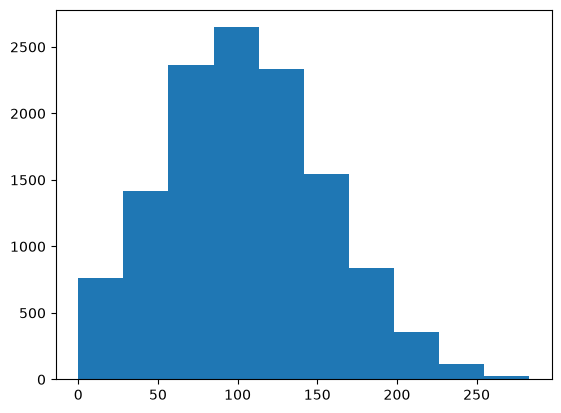

In [157]:
plt.hist(ad_performance["impressions"])
plt.show() 

#### ML

1. Build a model to predict, for a keyword-day, whether it will convert (orders > 0), or to predict sales. Your choice — justify it.
2. How did you split train/test, and why? What features did you use, and are any of them problematic?
3. Evaluate it with an appropriate metric. Would you ship this into the autonomous bidding engine? What would you monitor?

<b>Build the main dataset</b>

In [242]:
# Join campaigns metadata with ad performance
campaigns_ad_performance = ad_performance.merge(campaigns[["campaign_id", "product_category", "brand_id", "target_acos", "launch_date"]],
                  on="campaign_id", how="left", validate="many_to_one")

In [ ]:
# There is no orphan campaign_id by joining with ad_performance
campaigns_ad_performance.isna().sum()

date                0
campaign_id         0
keyword_id          0
keyword_text        0
match_type          0
impressions         0
clicks              0
spend               0
orders              0
sales               0
bid                 0
product_category    0
brand_id            0
target_acos         0
launch_date         0
dtype: int64

In [244]:
campaigns_ad_performance.info()

<class 'pandas.DataFrame'>
RangeIndex: 12400 entries, 0 to 12399
Data columns (total 15 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   date              12400 non-null  datetime64[us]
 1   campaign_id       12400 non-null  int64         
 2   keyword_id        12400 non-null  category      
 3   keyword_text      12400 non-null  str           
 4   match_type        12400 non-null  category      
 5   impressions       12400 non-null  int64         
 6   clicks            12400 non-null  int64         
 7   spend             12400 non-null  float64       
 8   orders            12400 non-null  int64         
 9   sales             12400 non-null  float64       
 10  bid               12400 non-null  float64       
 11  product_category  12400 non-null  category      
 12  brand_id          12400 non-null  category      
 13  target_acos       12400 non-null  float64       
 14  launch_date       12400 non-null 

In [245]:
campaigns_ad_performance.head()

,date,campaign_id,keyword_id,keyword_text,match_type,impressions,clicks,spend,orders,sales,bid,product_category,brand_id,target_acos,launch_date
0,2024-05-19,1005,5060,gift office,broad,95,0,0.00,0,0.00,0.71,office,brand_03,0.311,2024-02-18
1,2024-05-14,1022,5205,eco outdoor,phrase,97,4,3.58,1,17.93,0.89,outdoor,brand_12,0.152,2024-01-24
2,2024-06-25,1000,5008,mini outdoor,exact,87,0,0.00,0,0.00,0.78,outdoor,brand_01,0.260,2024-02-21
3,2024-06-06,1000,5005,deluxe outdoor,phrase,240,0,0.00,0,0.00,1.90,outdoor,brand_01,0.260,2024-02-21
4,2024-06-02,1019,5180,starter kitchen,exact,167,2,2.32,0,0.00,1.16,kitchen,brand_10,0.358,2024-02-07


In [247]:
# Feature engineering related to time
campaigns_ad_performance["month"] = campaigns_ad_performance["date"].dt.month
campaigns_ad_performance["day_of_week"] = campaigns_ad_performance["date"].dt.dayofweek
campaigns_ad_performance["days_since_launch"] = (campaigns_ad_performance["launch_date"] - campaigns_ad_performance["date"]).dt.days

# Build the target variable
campaigns_ad_performance["target"] = np.where(campaigns_ad_performance["orders"]>0, 1, 0)

In [ ]:
# Identify the imbalance proportion of the dataset
campaigns_ad_performance.target.value_counts(normalize=True)

target
0    0.902903
1    0.097097
Name: proportion, dtype: float64

<b>Build the train test set</b>

In [249]:
features = ['keyword_id', 'match_type',
       'impressions', 'clicks', 'spend', 'bid',
       'product_category', 'brand_id', 'target_acos', 'month',
       'day_of_week', 'days_since_launch']
target = 'target'

In [250]:
# Time based train test split - 
cut = int(len(campaigns_ad_performance) * 0.8)
train, test = campaigns_ad_performance.iloc[:cut], campaigns_ad_performance.iloc[cut:]

In [ ]:
X_train = train[features]
y_train = train[target]

X_test = test[features]
y_test = test[target]

In [286]:
# Imbalance consistent accross both samples
print(f"train {y_train.mean()} | test {y_test.mean()}")

train 0.09909274193548387 | test 0.08911290322580645


<b>Train model</b>

In [ ]:
neg, pos = (y_train == 0).sum(), (y_train == 1).sum()

In [252]:
model = XGBClassifier(
    scale_pos_weight=neg / pos,   # e.g. 900/100 = 9
    eval_metric="aucpr",          # PR-AUC suits imbalanced data
    n_estimators=500,
    learning_rate=0.05,
    enable_categorical=True
    
)
model.fit(X_train, y_train, eval_set=[(X_test, y_test)], verbose=False)

,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,None
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",'aucpr'
,feature_types feature_types: typing.Optional[typing.Sequence[str]].. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


<b>Evaluate</b>

In [272]:
y_pred = model.predict(X_test)

In [281]:
# Recall if the probability threshold is 0.5
recall = recall_score(y_test, y_pred)
print(f"Recall: {recall}")

precision = precision_score(y_test, y_pred)
print(f"Precision: {precision}")

Recall: 0.42081447963800905
Precision: 0.28353658536585363


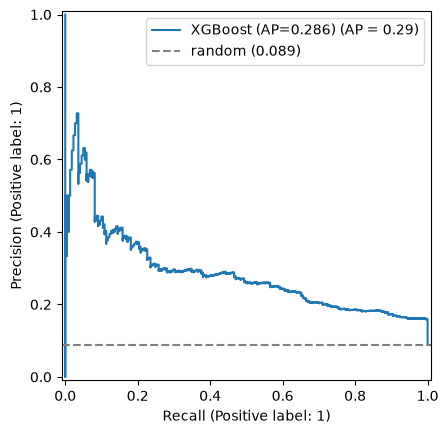

In [268]:
# Precision - Recall curve across different probability thresholds
proba = model.predict_proba(X_test)[:, 1]

ap = average_precision_score(y_test, proba)
baseline = y_test.mean() # share of positives = random guessing

disp = PrecisionRecallDisplay.from_predictions(y_test, proba, name=f"XGBoost (AP={ap:.3f})")
disp.ax_.axhline(baseline, ls="--", color="grey", label=f"random ({baseline:.3f})")
disp.ax_.legend()
plt.show()

<b>Conclusion</b>

If you guess randomly, of all the keyword-days baseline predicted would convert, only 8% actually did. The model is at 29%, so the performance is better. However, I would focus on maximizing the Recall/Coverage, I want to identify as many as possible keywords that will bring me value, with a reasonable precision.

I wouldn't ship this model right now. First I would:
- Monitor the train vs test performance for overfitting.
- Backtest/cross-valide to ensure robustness of the methodology.
- More features could still be found.
</br>

If I ship it, I would monitor:
- The production performance  (performance accuracy monitoring) + compare vs. performance at training. They should'nt be a big gap.
- Data drift, concept drift and bias of the production data vs training data.
  
</br>
The model predicts whether a keyword-day will convert, but it relies on same-day features that are only available at the end of the day, so it cannot be used to forecast conversions far in advance.</br>
A better angle to look at would be to use past information of the keyword and predict if the keyword will result in orders tomorrow. For that, I would need to lag the features. The business need reframes the method!